# 09 — t-SNE and temporal structure of the features: how much does x(t−N) tell about x(t)?

So far: `y(t)` (BCM charge) is inferred from the same shot's features `x(t)` (notebooks 08–08_06).
Next goal: infer `y(t)` from **past** features `x(t−N)`. That can only work as far as `x(t−N)` still carries the
information in `x(t)`. This notebook looks at that, on the segment datasets (`results/datasets/`, 16 features, valid shots
with beam only):

1. **t-SNE of all segments** — a 2-D map of the 16-feature state: do runs sit in different regions, is the charge organised?
2. **t-SNE inside each segment** (consecutive shots) — does the state drift smoothly or jump from shot to shot?
3. **How far the state moves in N shots** — distance between `x(t)` and `x(t−N)` on the map, and how often `x(t−N)` is
   among the nearest neighbours of `x(t)` in the original 16-D space
4. **Numbers** — autocorrelation of every feature at lag N (overall and shot-to-shot), and how well the whole `x(t)` is
   predicted from `x(t−N)` (Ridge, chronological split)

t-SNE keeps neighbourhoods, not global distances: clusters and trajectories are meaningful, absolute map distances only
roughly. Section 4 gives the quantitative answer.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import RidgeCV

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))
import vd_models as vm

OUT = REPO / "results" / "tsne"
OUT.mkdir(parents=True, exist_ok=True)

PER_SEGMENT = 1500          # shots per segment in the global map
BLOCK = 3000                # consecutive valid shots per segment in the per-segment maps
LAGS = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
K_NEIGHBOURS = 10
SEED = 0

CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"

segments, FEATURES = vm.load_segments(REPO / "results" / "datasets")
SEGS = list(segments)
COLOR = dict(zip(SEGS, CATEGORICAL))
for k, s in segments.items():
    s["good"] = s["train"] | s["test"]          # valid shots with beam
print(f"{len(SEGS)} segments, {len(FEATURES)} features: {FEATURES}")


def style(ax, grid=True):
    if grid:
        ax.grid(color=GRID, lw=0.6)
        ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


def fill_standardise(X, ref):
    """Median-fill NaN (median of ref rows) and standardise with the ref rows."""
    med = np.nanmedian(X[ref], axis=0)
    X = np.where(np.isnan(X), med, X)
    return (X - X[ref].mean(0)) / (X[ref].std(0) + 1e-12)

7 segments, 16 features: ['lab_laser_power', 'BTV_intensity', 'PGLA_drop', 'BTV_amplitude', 'PKI15A', 'BTV_mean_x', 'BTV_sigma_major', 'BTV_sigma_minor', 'BTV_tilt', 'BTV_ellipticity', 'SVD_s1', 'SVD_s2', 'SVD_s3', 'SVD_s4', 'SVD_s5', 'SVD_s6']


## 1. t-SNE of all segments together

Features standardised over all segments together (so differences between runs stay visible),
`PER_SEGMENT` random valid shots per segment.

In [2]:
rng = np.random.default_rng(SEED)
rows = []
for k, s in segments.items():
    idx = np.flatnonzero(s["good"])
    pick = np.sort(rng.choice(idx, size=min(PER_SEGMENT, len(idx)), replace=False))
    rows.append(pd.DataFrame({"segment": k, "row": pick, "time": pick / len(s["y"]), "charge": s["y"][pick]}))
sample = pd.concat(rows, ignore_index=True)
X_all = np.vstack([segments[k]["X"][g["row"]] for k, g in sample.groupby("segment", sort=False)])
Z_all = fill_standardise(X_all, np.ones(len(X_all), bool))

t0 = time.time()
emb = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z_all)
sample[["e1", "e2"]] = emb
print(f"t-SNE of {len(sample)} shots: {time.time() - t0:.0f} s")

t-SNE of 10500 shots: 14 s


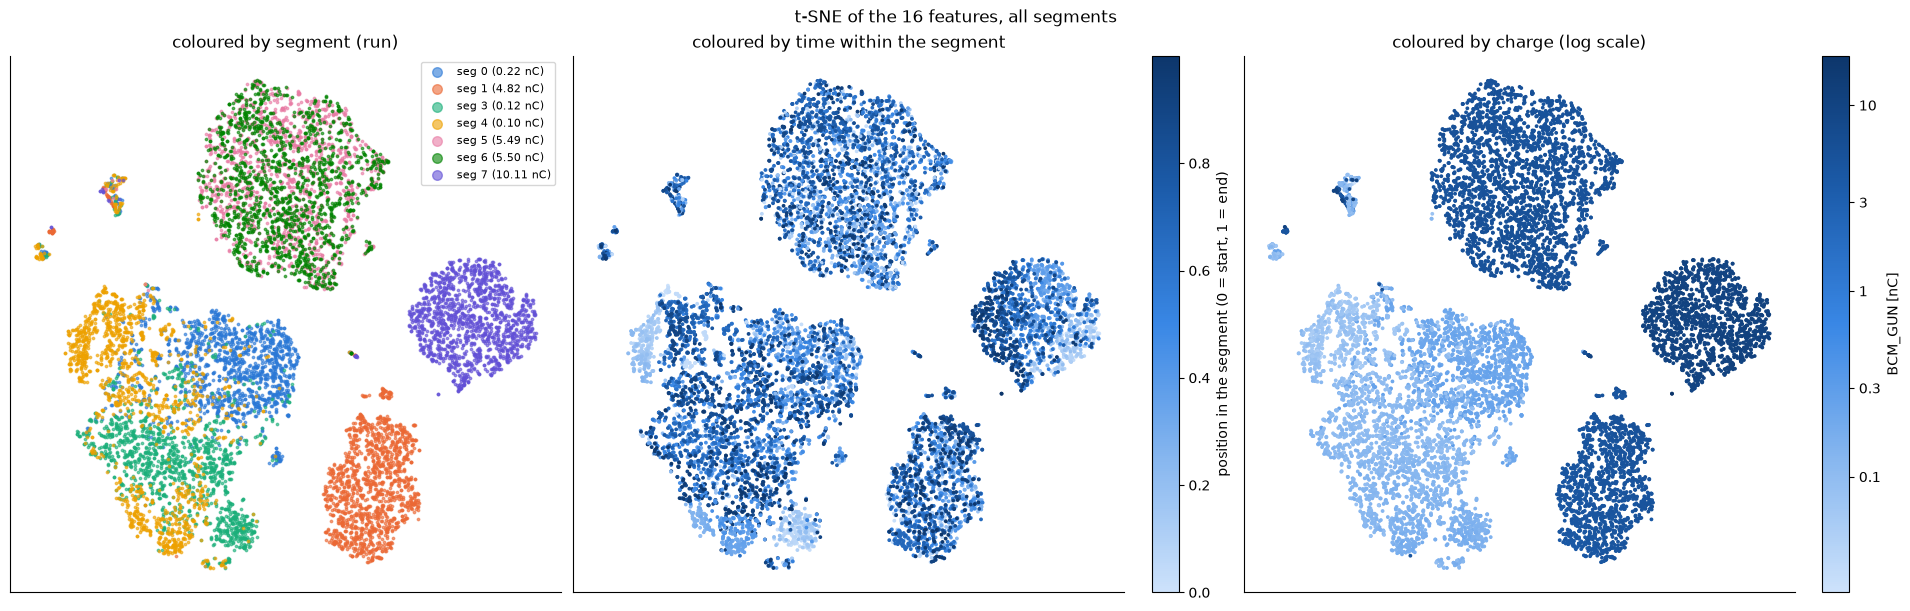

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), layout="constrained")
ax = axes[0]
for k in SEGS:
    g = sample[sample["segment"] == k]
    ax.scatter(g["e1"], g["e2"], s=3, color=COLOR[k], alpha=0.6, label=f"seg {k} ({segments[k]['y'][segments[k]['good']].mean():.2f} nC)")
ax.legend(fontsize=8, markerscale=4, loc="best")
ax.set_title("coloured by segment (run)")
sc = axes[1].scatter(sample["e1"], sample["e2"], s=3, c=sample["time"], cmap=SEQUENTIAL)
fig.colorbar(sc, ax=axes[1], label="position in the segment (0 = start, 1 = end)")
axes[1].set_title("coloured by time within the segment")
sc = axes[2].scatter(sample["e1"], sample["e2"], s=3, c=np.log10(sample["charge"]), cmap=SEQUENTIAL)
cb = fig.colorbar(sc, ax=axes[2], label="BCM_GUN [nC]")
cb.set_ticks(np.log10([0.1, 0.3, 1, 3, 10]), labels=["0.1", "0.3", "1", "3", "10"])
axes[2].set_title("coloured by charge (log scale)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    style(ax, grid=False)
fig.suptitle("t-SNE of the 16 features, all segments", fontsize=12)
fig.savefig(OUT / "tsne_all_segments.png", dpi=130, bbox_inches="tight");

## 2. t-SNE inside each segment, on consecutive shots

Per segment: the first `BLOCK` consecutive valid shots, features standardised on those shots. Coloured by time;
the black line follows 200 consecutive shots (a 'trajectory' of the state).

per-segment t-SNE: 29 s


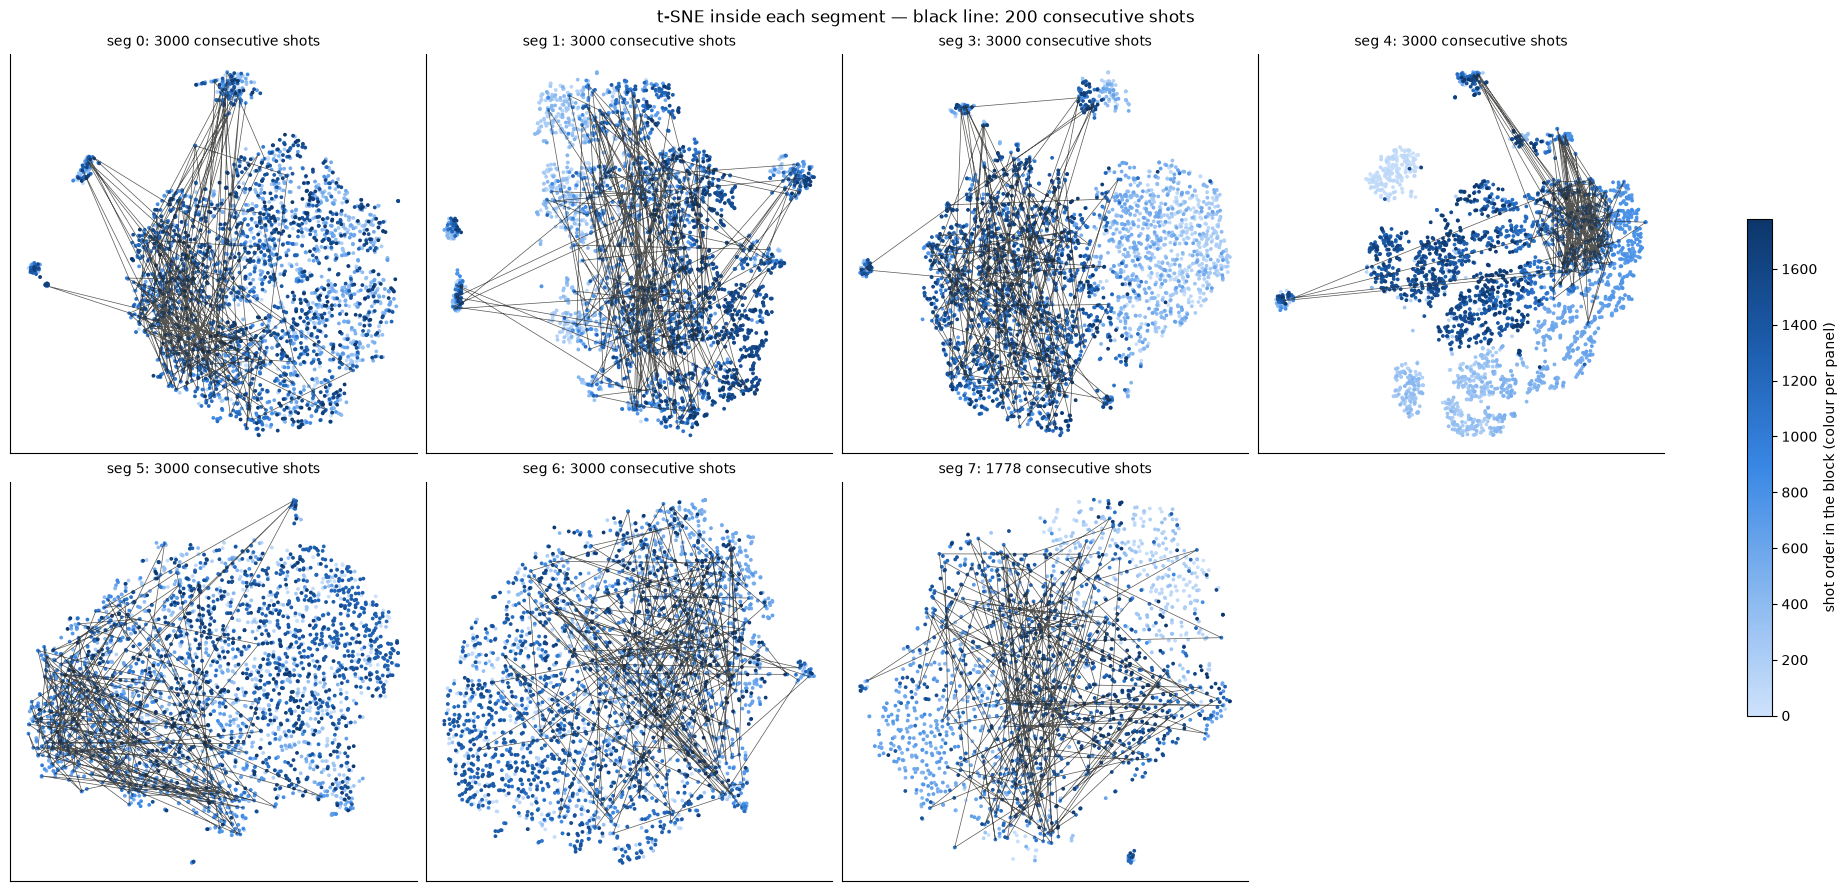

In [4]:
blocks = {}
t0 = time.time()
for k, s in segments.items():
    idx = np.flatnonzero(s["good"])[:BLOCK]
    Z = fill_standardise(s["X"][idx], np.ones(len(idx), bool))
    e = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z)
    blocks[k] = {"rows": idx, "Z": Z, "emb": e}
print(f"per-segment t-SNE: {time.time() - t0:.0f} s")

ncols = 4
nrows = int(np.ceil(len(SEGS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.4 * nrows), layout="constrained", squeeze=False)
for ax, k in zip(axes.ravel(), SEGS):
    b = blocks[k]
    sc = ax.scatter(b["emb"][:, 0], b["emb"][:, 1], s=3, c=np.arange(len(b["rows"])), cmap=SEQUENTIAL)
    path = slice(len(b["rows"]) // 2, len(b["rows"]) // 2 + 200)
    ax.plot(b["emb"][path, 0], b["emb"][path, 1], "-", color=INK, lw=0.5, alpha=0.8)
    ax.set_title(f"seg {k}: {len(b['rows'])} consecutive shots", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    style(ax, grid=False)
for ax in axes.ravel()[len(SEGS):]:
    ax.set_visible(False)
fig.colorbar(sc, ax=axes, shrink=0.6, label="shot order in the block (colour per panel)")
fig.suptitle("t-SNE inside each segment — black line: 200 consecutive shots", fontsize=12)
fig.savefig(OUT / "tsne_per_segment.png", dpi=130, bbox_inches="tight");

## 3. How far does the state move in N shots?

- **Map distance**: median distance on the t-SNE map between shot t and shot t−N, divided by the median distance of
  random pairs (1 = as far apart as two random shots of the block).
- **Neighbour test** (original 16-D standardised space, no t-SNE): fraction of shots t whose shot t−N is among the
  `K_NEIGHBOURS` nearest neighbours of t (chance level = K / block size).

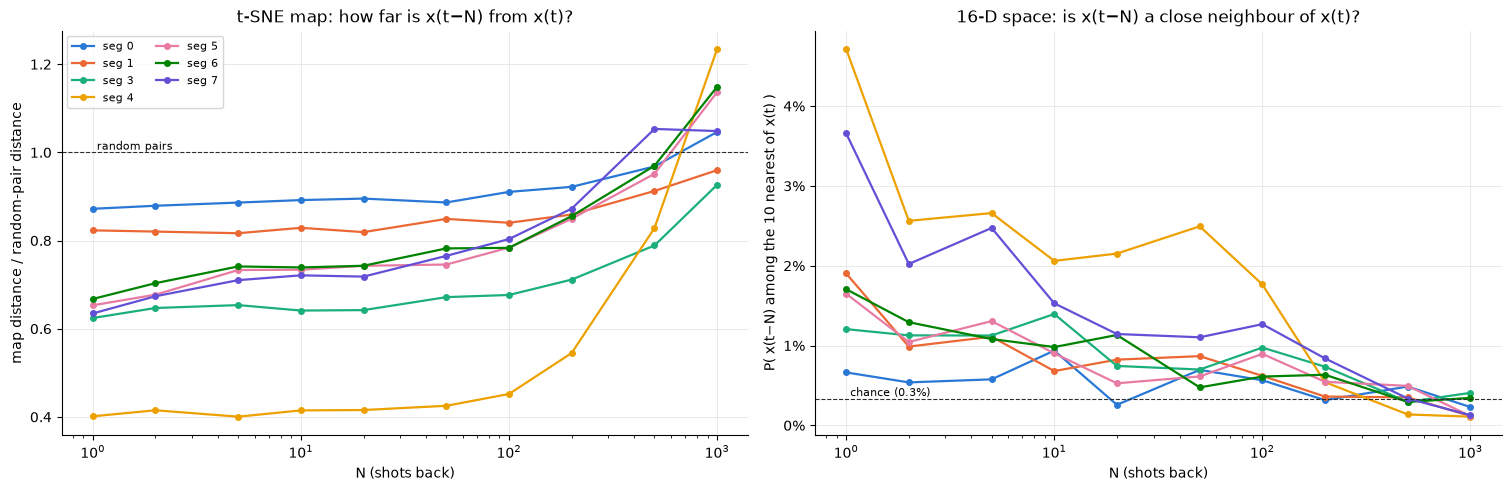

In [5]:
def lag_pairs(rows, n):
    """Positions i in the block where the shot n rows earlier is also in the block -> (i, j) with row[j] = row[i] - n."""
    where = {r: i for i, r in enumerate(rows)}
    i = np.array([p for p, r in enumerate(rows) if r - n in where])
    j = np.array([where[rows[p] - n] for p in i])
    return i, j


distance, neighbour = {}, {}
for k, b in blocks.items():
    e, rows_ = b["emb"], b["rows"]
    rnd_i, rnd_j = rng.integers(0, len(rows_), (2, 20000))
    random_dist = np.median(np.linalg.norm(e[rnd_i] - e[rnd_j], axis=1))
    nn_idx = NearestNeighbors(n_neighbors=K_NEIGHBOURS + 1).fit(b["Z"]).kneighbors(b["Z"], return_distance=False)[:, 1:]
    distance[k], neighbour[k] = {}, {}
    for n in LAGS:
        i, j = lag_pairs(rows_, n)
        if len(i) < 50:
            continue
        distance[k][n] = np.median(np.linalg.norm(e[i] - e[j], axis=1)) / random_dist
        neighbour[k][n] = np.mean([jj in nn_idx[ii] for ii, jj in zip(i, j)])
distance, neighbour = pd.DataFrame(distance), pd.DataFrame(neighbour)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for k in SEGS:
    axes[0].plot(distance.index, distance[k], "o-", color=COLOR[k], lw=1.6, ms=4, label=f"seg {k}")
    axes[1].plot(neighbour.index, neighbour[k], "o-", color=COLOR[k], lw=1.6, ms=4, label=f"seg {k}")
axes[0].axhline(1, color=INK, lw=0.8, ls="--")
axes[0].text(LAGS[0], 1.0, " random pairs", va="bottom", fontsize=8)
axes[0].set(xscale="log", xlabel="N (shots back)", ylabel="map distance / random-pair distance",
            title="t-SNE map: how far is x(t−N) from x(t)?")
chance = K_NEIGHBOURS / BLOCK
axes[1].axhline(chance, color=INK, lw=0.8, ls="--")
axes[1].text(LAGS[0], chance, f" chance ({chance:.1%})", va="bottom", fontsize=8)
axes[1].set(xscale="log", xlabel="N (shots back)", ylabel=f"P( x(t−N) among the {K_NEIGHBOURS} nearest of x(t) )",
            title="16-D space: is x(t−N) a close neighbour of x(t)?")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(fontsize=8, ncol=2)
for ax in axes:
    style(ax)
fig.savefig(OUT / "lag_distance_neighbours.png", dpi=130, bbox_inches="tight");

## 4. In numbers: correlation of x(t) with x(t−N)

**Per feature**: correlation between `x_f(t)` and `x_f(t−N)` over valid shot pairs, averaged over segments —
**overall** (raw values: slow drift included) and **shot-to-shot** (51-shot rolling mean removed first).

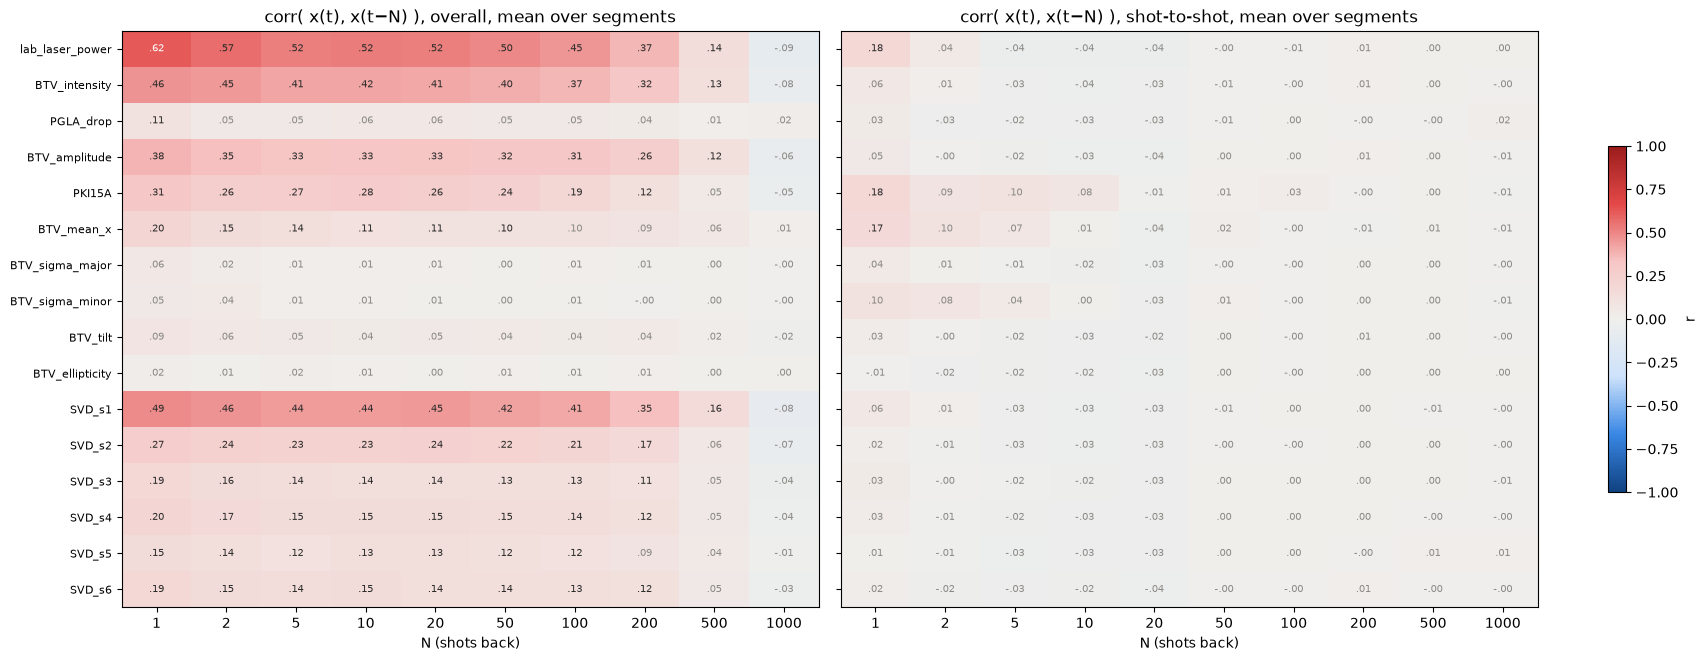

In [6]:
def lag_corr(a, valid, n, fast=False):
    a = vm.fast(a) if fast else a
    ok = valid[n:] & valid[:-n] & ~np.isnan(a[n:]) & ~np.isnan(a[:-n])
    return np.corrcoef(a[n:][ok], a[:-n][ok])[0, 1] if ok.sum() > 50 else np.nan


ac = {kind: pd.DataFrame({n: [np.nanmean([lag_corr(segments[k]["X"][:, f], segments[k]["good"], n, kind == "shot-to-shot")
                                          for k in SEGS]) for f in range(len(FEATURES))] for n in LAGS}, index=FEATURES)
      for kind in ["overall", "shot-to-shot"]}

DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), layout="constrained")
for ax, (kind, table) in zip(axes, ac.items()):
    im = ax.imshow(table, cmap=DIV, vmin=-1, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{v:.2f}".replace("0.", "."), ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else (INK if abs(v) >= 0.1 else MUTED))
    ax.set_xticks(range(len(LAGS)), LAGS)
    ax.set_yticks(range(len(FEATURES)), FEATURES if ax is axes[0] else [], fontsize=8)
    ax.set(xlabel="N (shots back)", title=f"corr( x(t), x(t−N) ), {kind}, mean over segments")
fig.colorbar(im, ax=axes, shrink=0.6, label="r")
fig.savefig(OUT / "feature_autocorrelation.png", dpi=130, bbox_inches="tight");

**All features at once**: how much of `x(t)` can be predicted from `x(t−N)`?
Per segment and lag, one Ridge model per feature on standardised features, trained on the first 70% of the segment
and scored on the last 30% (R², averaged over the 16 features). For reference, **persistence** = predicting `x(t)`
simply as `x(t−N)`.

segment,0,1,3,4,5,6,7
N,,,,,,,
1,-0.15,0.07,-0.01,0.05,0.15,0.18,0.12
2,-0.17,0.06,-0.06,0.00,0.15,0.17,-0.05
5,-0.18,0.06,-0.04,-0.00,0.14,0.14,-0.15
10,-0.18,0.07,-0.06,0.01,0.14,0.14,-0.06
20,-0.20,0.07,-0.02,0.00,0.14,0.14,-0.07
50,-0.19,0.05,-0.05,-0.02,0.12,0.13,-0.08
100,-0.21,0.03,-0.07,-0.10,0.11,0.13,-0.09
200,-0.22,-0.03,-0.09,-0.28,0.07,0.09,-0.11
500,-0.33,-0.02,-0.10,-0.57,0.00,-0.03,-0.10


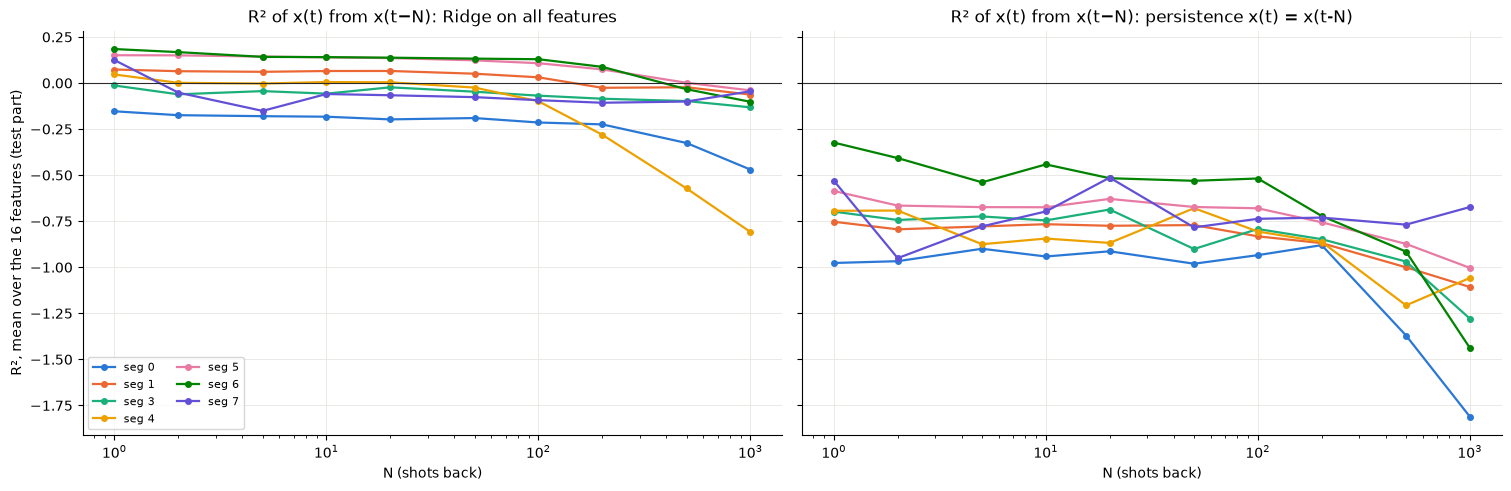

In [7]:
def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)


rows = []
for k, s in segments.items():
    Z = fill_standardise(s["X"], s["train"])
    good = s["good"]
    split = s["cut"]
    for n in LAGS:
        src, dst = np.arange(len(Z) - n), np.arange(n, len(Z))       # x(t-n) -> x(t)
        ok = good[src] & good[dst]
        tr, te = ok & (dst < split), ok & (dst >= split)
        if tr.sum() < 200 or te.sum() < 100:
            continue
        model = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(Z[src[tr]], Z[dst[tr]])
        pred = model.predict(Z[src[te]])
        rows.append({"segment": k, "N": n,
                     "Ridge on all features": np.mean([r2(Z[dst[te], f], pred[:, f]) for f in range(Z.shape[1])]),
                     "persistence x(t) = x(t-N)": np.mean([r2(Z[dst[te], f], Z[src[te], f]) for f in range(Z.shape[1])])})
pred_x = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained", sharey=True)
for ax, col in zip(axes, ["Ridge on all features", "persistence x(t) = x(t-N)"]):
    for k in SEGS:
        g = pred_x[pred_x["segment"] == k]
        ax.plot(g["N"], g[col], "o-", color=COLOR[k], lw=1.6, ms=4, label=f"seg {k}")
    ax.axhline(0, color=INK, lw=0.8)
    ax.set(xscale="log", xlabel="N (shots back)", title=f"R² of x(t) from x(t−N): {col}")
    style(ax)
axes[0].set_ylabel("R², mean over the 16 features (test part)")
axes[0].legend(fontsize=8, ncol=2)
fig.savefig(OUT / "predict_x_from_past.png", dpi=130, bbox_inches="tight")
pred_x.pivot(index="N", columns="segment", values="Ridge on all features").round(2)